In [2]:
# Library for sending HTTP requests to websites
import requests

# Library for extracting information from HTML
from bs4 import BeautifulSoup

# Library for storing and analyzing data
import pandas as pd

# Library for handling delays between requests
import time

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Website URL
url = "https://books.toscrape.com/"

# Send request to the website
response = requests.get(url, timeout=15)

# Display connection information
print("Website:", url)
print("Status Code:", response.status_code)
print("Website Connection Successful:",
      response.status_code == 200)

Website: https://books.toscrape.com/
Status Code: 200
Website Connection Successful: True


In [4]:
# Extract HTML content from the website
soup = BeautifulSoup(response.text, 'html.parser')

# Display the webpage title
print("Website Title:", soup.title.text.strip())

# Display the first 1000 characters of HTML
print("\nHTML Preview:\n")
print(soup.prettify()[:1000])

Website Title: All products | Books to Scrape - Sandbox

HTML Preview:

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!-->
<html class="no-js" lang="en-us">
 <!--<![endif]-->
 <head>
  <title>
   All products | Books to Scrape - Sandbox
  </title>
  <meta content="text/html; charset=utf-8" http-equiv="content-type"/>
  <meta content="24th Jun 2016 09:29" name="created"/>
  <meta content="" name="description"/>
  <meta content="width=device-width" name="viewport"/>
  <meta content="NOARCHIVE,NOCACHE" name="robots"/>
  <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
  <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
  <link href="static/oscar/favicon.ico" rel="shortcut icon"

In [5]:
# Find all product containers on the current page
products = soup.find_all('article', class_='product_pod')

print("Total products on this page:", len(products))

# Inspect the first product
print("\nFirst product HTML:\n")
print(products[0].prettify())

Total products on this page: 20

First product HTML:

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [6]:
from urllib.parse import urljoin

# Select the first product
product = products[0]

# Extract product title
title = product.select_one('h3 a')['title']

# Extract price
price = product.select_one('.price_color').get_text(strip=True)

# Extract rating
rating = product.select_one('.star-rating')['class'][-1]

# Extract availability
availability = product.select_one('.availability').get_text(strip=True)

# Extract product URL
product_link = product.select_one('h3 a')['href']
product_url = urljoin(url, product_link)

# Extract image URL
image_link = product.select_one('.image_container img')['src']
image_url = urljoin(url, image_link)

# Display extracted information
print("PRODUCT INFORMATION")
print("-" * 40)
print("Title:", title)
print("Price:", price)
print("Rating:", rating)
print("Availability:", availability)
print("Product URL:", product_url)
print("Image URL:", image_url)

PRODUCT INFORMATION
----------------------------------------
Title: A Light in the Attic
Price: Â£51.77
Rating: Three
Availability: In stock
Product URL: https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
Image URL: https://books.toscrape.com/media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg


In [7]:
def extract_product(product, page_url):

    # Extract title
    title = product.select_one('h3 a')['title']

    # Extract price and fix encoding
    price = product.select_one('.price_color').get_text(strip=True)
    price = price.replace('Â£', '£')

    # Convert price into a numerical value
    price_value = float(price.replace('£', '').strip())

    # Extract rating
    rating = product.select_one('.star-rating')['class'][-1]

    # Extract availability
    availability = product.select_one('.availability').get_text(strip=True)

    # Extract product URL
    product_link = product.select_one('h3 a')['href']
    product_url = urljoin(page_url, product_link)

    # Extract image URL
    image_link = product.select_one('.image_container img')['src']
    image_url = urljoin(page_url, image_link)

    # Return structured information
    return {
        'title': title,
        'price': price_value,
        'currency': 'GBP',
        'rating': rating,
        'availability': availability,
        'product_url': product_url,
        'image_url': image_url
    }


# Test the function on the first product
first_product_data = extract_product(products[0], url)

print("Extracted product data:")
print(first_product_data)

Extracted product data:
{'title': 'A Light in the Attic', 'price': 51.77, 'currency': 'GBP', 'rating': 'Three', 'availability': 'In stock', 'product_url': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html', 'image_url': 'https://books.toscrape.com/media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg'}


In [8]:
# Extract information from every product on the current page
page_products = []

for product in products:
    product_data = extract_product(product, url)
    page_products.append(product_data)

# Convert extracted data into a Pandas DataFrame
page_df = pd.DataFrame(page_products)

# Display the results
print("Total products extracted:", len(page_df))

display(page_df.head(10))

Total products extracted: 20


,title,price,currency,rating,availability,product_url,image_url
0,A Light in the Attic,51.77,GBP,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,https://books.toscrape.com/media/cache/2c/da/2...
1,Tipping the Velvet,53.74,GBP,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,https://books.toscrape.com/media/cache/26/0c/2...
2,Soumission,50.10,GBP,One,In stock,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...
3,Sharp Objects,47.82,GBP,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,https://books.toscrape.com/media/cache/32/51/3...
4,Sapiens: A Brief History of Humankind,54.23,GBP,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,https://books.toscrape.com/media/cache/be/a5/b...
5,The Requiem Red,22.65,GBP,One,In stock,https://books.toscrape.com/catalogue/the-requi...,https://books.toscrape.com/media/cache/68/33/6...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-dirty...,https://books.toscrape.com/media/cache/92/27/9...
7,The Coming Woman: A Novel Based on the Life of...,17.93,GBP,Three,In stock,https://books.toscrape.com/catalogue/the-comin...,https://books.toscrape.com/media/cache/3d/54/3...
8,The Boys in the Boat: Nine Americans and Their...,22.60,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-boys-...,https://books.toscrape.com/media/cache/66/88/6...
9,The Black Maria,52.15,GBP,One,In stock,https://books.toscrape.com/catalogue/the-black...,https://books.toscrape.com/media/cache/58/46/5...


In [9]:
# Check the structure and data types
print("Dataset Information:")
page_df.info()

# Check for missing values
print("\nMissing Values:")
print(page_df.isnull().sum())

# Check for duplicate products
print("\nDuplicate Product URLs:")
print(page_df['product_url'].duplicated().sum())

# Check basic statistics for prices
print("\nPrice Statistics:")
print(page_df['price'].describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         20 non-null     object 
 1   price         20 non-null     float64
 2   currency      20 non-null     object 
 3   rating        20 non-null     object 
 4   availability  20 non-null     object 
 5   product_url   20 non-null     object 
 6   image_url     20 non-null     object 
dtypes: float64(1), object(6)
memory usage: 1.2+ KB

Missing Values:
title           0
price           0
currency        0
rating          0
availability    0
product_url     0
image_url       0
dtype: int64

Duplicate Product URLs:
0

Price Statistics:
count    20.000000
mean     38.048500
std      15.135231
min      13.990000
25%      22.637500
50%      41.380000
75%      51.865000
max      57.250000
Name: price, dtype: float64


In [10]:
# Check unique values in categorical columns
print("Unique Ratings:")
print(page_df['rating'].value_counts())

print("\nAvailability Status:")
print(page_df['availability'].value_counts())

print("\nCurrency Distribution:")
print(page_df['currency'].value_counts())

# Check invalid or unrealistic prices
print("\nInvalid Prices:", (page_df['price'] <= 0).sum())

# Check URL validity
print("\nProduct URLs starting with HTTPS:",
      page_df['product_url'].str.startswith('https://').all())

print("Image URLs starting with HTTPS:",
      page_df['image_url'].str.startswith('https://').all())

Unique Ratings:
rating
One      6
Five     4
Four     4
Three    3
Two      3
Name: count, dtype: int64

Availability Status:
availability
In stock    20
Name: count, dtype: int64

Currency Distribution:
currency
GBP    20
Name: count, dtype: int64

Invalid Prices: 0

Product URLs starting with HTTPS: True
Image URLs starting with HTTPS: True


In [11]:
# Find the next page link
next_button = soup.select_one('li.next a')

if next_button:
    next_page_url = urljoin(url, next_button['href'])
    print("Next page found:", next_page_url)
else:
    print("No next page found.")

Next page found: https://books.toscrape.com/catalogue/page-2.html


In [12]:
def scrape_all_pages(start_url):
    all_products = []
    current_url = start_url
    page_number = 1

    while current_url:

        print(f"Scraping page {page_number}...")

        try:
            response = requests.get(current_url, timeout=15)
            response.raise_for_status()

            page_soup = BeautifulSoup(response.text, 'html.parser')

            products = page_soup.find_all(
                'article',
                class_='product_pod'
            )

            for product in products:
                try:
                    product_data = extract_product(product, current_url)
                    product_data['page_number'] = page_number
                    all_products.append(product_data)

                except (AttributeError, KeyError, ValueError) as e:
                    print("Product extraction error:", e)

            # Find the next page
            next_button = page_soup.select_one('li.next a')

            if next_button:
                current_url = urljoin(
                    current_url,
                    next_button['href']
                )
                page_number += 1
                time.sleep(1)

            else:
                current_url = None

        except requests.exceptions.RequestException as e:
            print(f"Request failed on page {page_number}: {e}")
            break

    print("\nScraping completed!")
    print("Total pages processed:", page_number)
    print("Total products collected:", len(all_products))

    return pd.DataFrame(all_products)

In [13]:
# Scrape all catalogue pages
all_books_df = scrape_all_pages("https://books.toscrape.com/")

# Display the first 10 products
display(all_books_df.head(10))

# Display dataset dimensions
print("\nDataset Shape:", all_books_df.shape)

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...

Scraping

,title,price,currency,rating,availability,product_url,image_url,page_number
0,A Light in the Attic,51.77,GBP,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,https://books.toscrape.com/media/cache/2c/da/2...,1
1,Tipping the Velvet,53.74,GBP,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,https://books.toscrape.com/media/cache/26/0c/2...,1
2,Soumission,50.10,GBP,One,In stock,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...,1
3,Sharp Objects,47.82,GBP,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,https://books.toscrape.com/media/cache/32/51/3...,1
4,Sapiens: A Brief History of Humankind,54.23,GBP,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,https://books.toscrape.com/media/cache/be/a5/b...,1
5,The Requiem Red,22.65,GBP,One,In stock,https://books.toscrape.com/catalogue/the-requi...,https://books.toscrape.com/media/cache/68/33/6...,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-dirty...,https://books.toscrape.com/media/cache/92/27/9...,1
7,The Coming Woman: A Novel Based on the Life of...,17.93,GBP,Three,In stock,https://books.toscrape.com/catalogue/the-comin...,https://books.toscrape.com/media/cache/3d/54/3...,1
8,The Boys in the Boat: Nine Americans and Their...,22.60,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-boys-...,https://books.toscrape.com/media/cache/66/88/6...,1
9,The Black Maria,52.15,GBP,One,In stock,https://books.toscrape.com/catalogue/the-black...,https://books.toscrape.com/media/cache/58/46/5...,1



Dataset Shape: (1000, 8)


In [14]:
# Complete dataset quality report

print("DATASET INFORMATION")
print("-" * 40)
all_books_df.info()

print("\nMISSING VALUES")
print("-" * 40)
print(all_books_df.isnull().sum())

print("\nDUPLICATE PRODUCT URLS")
print("-" * 40)
print(all_books_df['product_url'].duplicated().sum())

print("\nINVALID PRICES")
print("-" * 40)
print((all_books_df['price'] <= 0).sum())

print("\nPRODUCTS PER PAGE")
print("-" * 40)
print(all_books_df['page_number'].value_counts().sort_index())

print("\nUNIQUE PRODUCTS")
print("-" * 40)
print(all_books_df['title'].nunique())

DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1000 non-null   object 
 1   price         1000 non-null   float64
 2   currency      1000 non-null   object 
 3   rating        1000 non-null   object 
 4   availability  1000 non-null   object 
 5   product_url   1000 non-null   object 
 6   image_url     1000 non-null   object 
 7   page_number   1000 non-null   int64  
dtypes: float64(1), int64(1), object(6)
memory usage: 62.6+ KB

MISSING VALUES
----------------------------------------
title           0
price           0
currency        0
rating          0
availability    0
product_url     0
image_url       0
page_number     0
dtype: int64

DUPLICATE PRODUCT URLS
----------------------------------------
0

INVALID PRICES
----------------------------------------
0



In [15]:
# Find titles that appear more than once
duplicate_titles = all_books_df[
    all_books_df['title'].duplicated(keep=False)
].sort_values('title')

print("Number of records with repeated titles:",
      len(duplicate_titles))

print("\nRepeated title details:")

display(
    duplicate_titles[
        ['title', 'price', 'rating', 'product_url', 'page_number']
    ]
)

Number of records with repeated titles: 2

Repeated title details:


,title,price,rating,product_url,page_number
236,The Star-Touched Queen,46.02,Five,https://books.toscrape.com/catalogue/the-star-...,12
358,The Star-Touched Queen,32.30,Five,https://books.toscrape.com/catalogue/the-star-...,18


In [16]:
# Create a separate cleaned dataset
cleaned_books_df = all_books_df.copy()

# Clean text columns
text_columns = [
    'title',
    'currency',
    'rating',
    'availability',
    'product_url',
    'image_url'
]

for column in text_columns:
    cleaned_books_df[column] = (
        cleaned_books_df[column].str.strip()
    )

# Convert star ratings into numerical values
rating_mapping = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}

cleaned_books_df['rating_score'] = (
    cleaned_books_df['rating'].map(rating_mapping)
)

# Create price categories
cleaned_books_df['price_category'] = pd.cut(
    cleaned_books_df['price'],
    bins=[0, 20, 40, 60, float('inf')],
    labels=['Budget', 'Moderate', 'Expensive', 'Premium']
)

# Display cleaned dataset
print("Cleaned Dataset Shape:", cleaned_books_df.shape)

display(cleaned_books_df.head(10))

print("\nMissing Values After Cleaning:")
print(cleaned_books_df.isnull().sum())

Cleaned Dataset Shape: (1000, 10)


,title,price,currency,rating,availability,product_url,image_url,page_number,rating_score,price_category
0,A Light in the Attic,51.77,GBP,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,https://books.toscrape.com/media/cache/2c/da/2...,1,3,Expensive
1,Tipping the Velvet,53.74,GBP,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,https://books.toscrape.com/media/cache/26/0c/2...,1,1,Expensive
2,Soumission,50.10,GBP,One,In stock,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...,1,1,Expensive
3,Sharp Objects,47.82,GBP,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,https://books.toscrape.com/media/cache/32/51/3...,1,4,Expensive
4,Sapiens: A Brief History of Humankind,54.23,GBP,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,https://books.toscrape.com/media/cache/be/a5/b...,1,5,Expensive
5,The Requiem Red,22.65,GBP,One,In stock,https://books.toscrape.com/catalogue/the-requi...,https://books.toscrape.com/media/cache/68/33/6...,1,1,Moderate
6,The Dirty Little Secrets of Getting Your Dream...,33.34,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-dirty...,https://books.toscrape.com/media/cache/92/27/9...,1,4,Moderate
7,The Coming Woman: A Novel Based on the Life of...,17.93,GBP,Three,In stock,https://books.toscrape.com/catalogue/the-comin...,https://books.toscrape.com/media/cache/3d/54/3...,1,3,Budget
8,The Boys in the Boat: Nine Americans and Their...,22.60,GBP,Four,In stock,https://books.toscrape.com/catalogue/the-boys-...,https://books.toscrape.com/media/cache/66/88/6...,1,4,Moderate
9,The Black Maria,52.15,GBP,One,In stock,https://books.toscrape.com/catalogue/the-black...,https://books.toscrape.com/media/cache/58/46/5...,1,1,Expensive



Missing Values After Cleaning:
title             0
price             0
currency          0
rating            0
availability      0
product_url       0
image_url         0
page_number       0
rating_score      0
price_category    0
dtype: int64


In [17]:
# Overall price analysis

print("BOOK PRICE ANALYSIS")
print("=" * 45)

print("Average Price: £", round(cleaned_books_df['price'].mean(), 2))
print("Median Price: £", round(cleaned_books_df['price'].median(), 2))
print("Minimum Price: £", cleaned_books_df['price'].min())
print("Maximum Price: £", cleaned_books_df['price'].max())
print("Standard Deviation: £", round(cleaned_books_df['price'].std(), 2))

# Price category distribution
print("\nPRICE CATEGORY DISTRIBUTION")
print("=" * 45)

price_distribution = (
    cleaned_books_df['price_category']
    .value_counts()
    .reindex(['Budget', 'Moderate', 'Expensive', 'Premium'])
)

print(price_distribution)

# Percentage distribution
print("\nPRICE CATEGORY PERCENTAGES")
print("=" * 45)

print(
    (price_distribution / len(cleaned_books_df) * 100)
    .round(2)
)

BOOK PRICE ANALYSIS
Average Price: £ 35.07
Median Price: £ 35.98
Minimum Price: £ 10.0
Maximum Price: £ 59.99
Standard Deviation: £ 14.45

PRICE CATEGORY DISTRIBUTION
price_category
Budget       196
Moderate     401
Expensive    403
Premium        0
Name: count, dtype: int64

PRICE CATEGORY PERCENTAGES
price_category
Budget       19.6
Moderate     40.1
Expensive    40.3
Premium       0.0
Name: count, dtype: float64


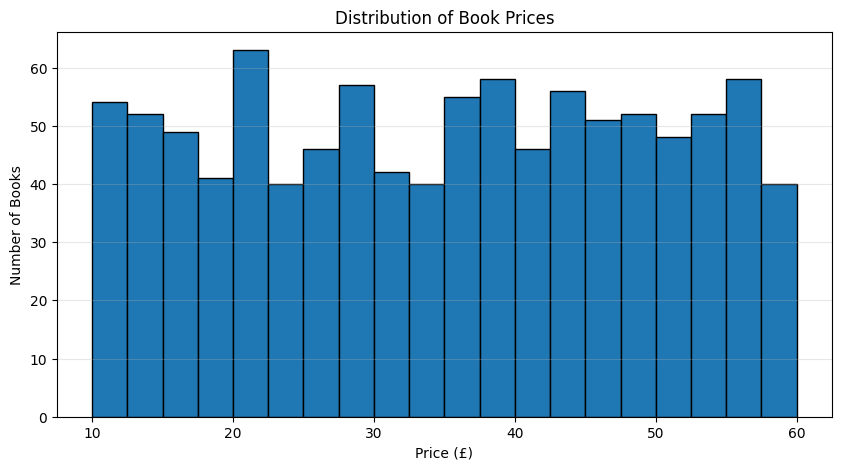

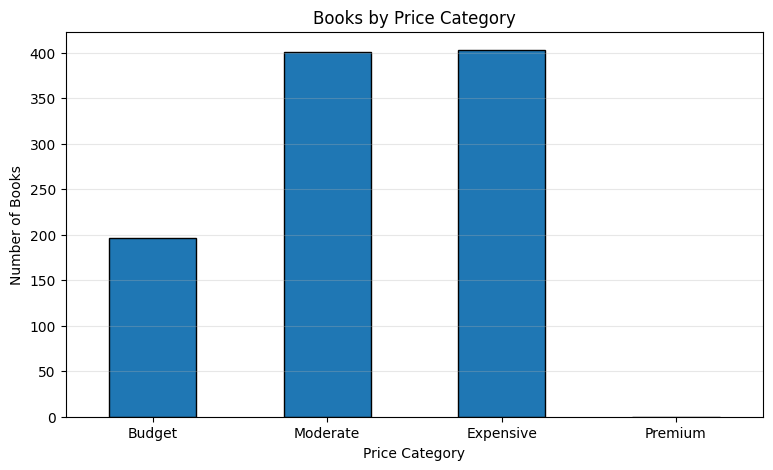

In [18]:
import matplotlib.pyplot as plt

# Chart 1: Distribution of book prices
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_books_df['price'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Book Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Books')
plt.grid(axis='y', alpha=0.3)

plt.show()


# Chart 2: Price category distribution
plt.figure(figsize=(9, 5))

price_distribution.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Books by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Number of Books')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [19]:
# Rating distribution
rating_distribution = (
    cleaned_books_df['rating_score']
    .value_counts()
    .sort_index()
)

print("RATING DISTRIBUTION")
print("=" * 40)

print(rating_distribution)

# Average rating
average_rating = cleaned_books_df['rating_score'].mean()

print("\nAverage Rating:", round(average_rating, 2), "/ 5")

# Percentage of highly rated books
highly_rated = cleaned_books_df[
    cleaned_books_df['rating_score'] >= 4
]

print("\nHighly Rated Books (4 or 5 stars):",
      len(highly_rated))

print("Percentage of Highly Rated Books:",
      round(len(highly_rated) / len(cleaned_books_df) * 100, 2),
      "%")

# Top 10 highest-rated books
top_rated_books = cleaned_books_df[
    cleaned_books_df['rating_score'] == 5
].sort_values('price', ascending=False)

print("\nTOP 10 FIVE-STAR BOOKS")
display(
    top_rated_books[
        ['title', 'price', 'rating', 'availability']
    ].head(10)
)

RATING DISTRIBUTION
rating_score
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Average Rating: 2.92 / 5

Highly Rated Books (4 or 5 stars): 375
Percentage of Highly Rated Books: 37.5 %

TOP 10 FIVE-STAR BOOKS


,title,price,rating,availability
560,The Barefoot Contessa Cookbook,59.92,Five,In stock
812,Life Without a Recipe,59.04,Five,In stock
637,Approval Junkie: Adventures in Caring Too Much,58.81,Five,In stock
379,How to Speak Golf: An Illustrated Guide to Lin...,58.32,Five,In stock
631,Digital Fortress,58.00,Five,In stock
545,The Sound Of Love,57.84,Five,In stock
910,Travels with Charley: In Search of America,57.82,Five,In stock
309,El Deafo,57.62,Five,In stock
898,H is for Hawk,57.42,Five,In stock
100,Immunity: How Elie Metchnikoff Changed the Cou...,57.36,Five,In stock


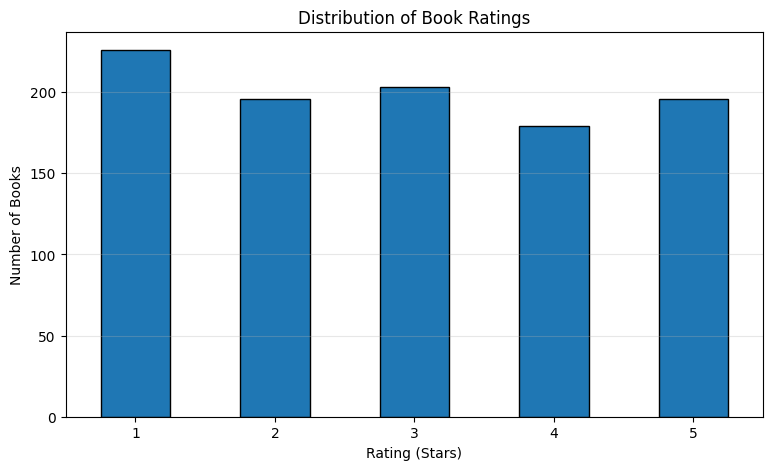

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

rating_distribution.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Book Ratings')
plt.xlabel('Rating (Stars)')
plt.ylabel('Number of Books')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [21]:
# Average price by rating
price_by_rating = (
    cleaned_books_df
    .groupby('rating_score', observed=True)['price']
    .agg(['mean', 'median', 'count'])
    .round(2)
)

print("PRICE ANALYSIS BY RATING")
print("=" * 45)

display(price_by_rating)

# Correlation between price and rating
correlation = cleaned_books_df[
    ['price', 'rating_score']
].corr()

print("\nPRICE-RATING CORRELATION:")
display(correlation)

PRICE ANALYSIS BY RATING


,mean,median,count
rating_score,,,
1,34.56,34.77,226
2,34.81,36.22,196
3,34.69,33.78,203
4,36.09,37.80,179
5,35.37,36.90,196



PRICE-RATING CORRELATION:


,price,rating_score
price,1.000000,0.028166
rating_score,0.028166,1.000000


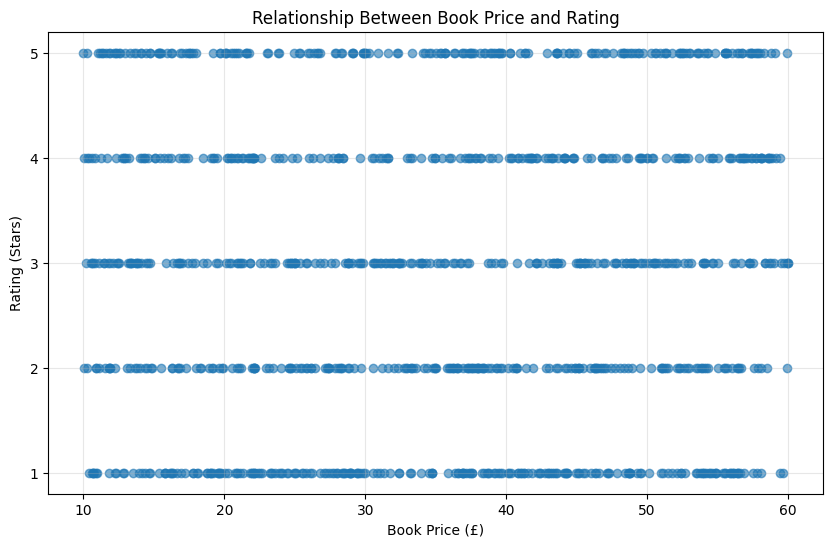

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    cleaned_books_df['price'],
    cleaned_books_df['rating_score'],
    alpha=0.6
)

plt.title('Relationship Between Book Price and Rating')
plt.xlabel('Book Price (£)')
plt.ylabel('Rating (Stars)')
plt.yticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.3)

plt.show()

In [23]:
availability_analysis = (
    cleaned_books_df['availability']
    .value_counts()
)

print("BOOK AVAILABILITY ANALYSIS")
print("=" * 40)

print(availability_analysis)

print("\nAvailability Percentage:")

print(
    (availability_analysis / len(cleaned_books_df) * 100)
    .round(2)
)

BOOK AVAILABILITY ANALYSIS
availability
In stock    1000
Name: count, dtype: int64

Availability Percentage:
availability
In stock    100.0
Name: count, dtype: float64


In [24]:
# Top 10 Most Expensive Books
most_expensive = cleaned_books_df.sort_values(
    by='price',
    ascending=False
)[['title', 'price', 'rating', 'availability']].head(10)

print("TOP 10 MOST EXPENSIVE BOOKS")
display(most_expensive)


# Top 10 Least Expensive Books
least_expensive = cleaned_books_df.sort_values(
    by='price',
    ascending=True
)[['title', 'price', 'rating', 'availability']].head(10)

print("\nTOP 10 LEAST EXPENSIVE BOOKS")
display(least_expensive)

TOP 10 MOST EXPENSIVE BOOKS


,title,price,rating,availability
648,The Perfect Play (Play by Play #1),59.99,Three,In stock
617,Last One Home (New Beginnings #1),59.98,Three,In stock
860,Civilization and Its Discontents,59.95,Two,In stock
560,The Barefoot Contessa Cookbook,59.92,Five,In stock
366,The Diary of a Young Girl,59.90,Three,In stock
657,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,Three,In stock
133,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,One,In stock
387,Boar Island (Anna Pigeon #19),59.48,Three,In stock
549,The Man Who Mistook His Wife for a Hat and Oth...,59.45,Four,In stock
393,The Improbability of Love,59.45,One,In stock



TOP 10 LEAST EXPENSIVE BOOKS


,title,price,rating,availability
638,An Abundance of Katherines,10.00,Five,In stock
501,The Origin of Species,10.01,Four,In stock
716,The Tipping Point: How Little Things Can Make ...,10.02,Two,In stock
84,Patience,10.16,Three,In stock
302,Greek Mythic History,10.23,Five,In stock
558,The Fellowship of the Ring (The Lord of the Ri...,10.27,Two,In stock
479,History of Beauty,10.29,Four,In stock
242,The Lucifer Effect: Understanding How Good Peo...,10.40,One,In stock
434,"NaNo What Now? Finding your editing process, r...",10.41,Four,In stock
274,Pet Sematary,10.56,Three,In stock


<Figure size 1000x600 with 0 Axes>

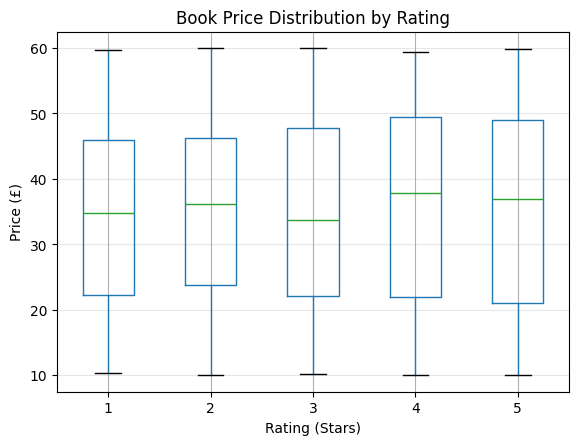

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

cleaned_books_df.boxplot(
    column='price',
    by='rating_score'
)

plt.title('Book Price Distribution by Rating')
plt.suptitle('')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price (£)')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [26]:
# Export cleaned dataset
cleaned_books_df.to_csv(
    'scraped_books_cleaned.csv',
    index=False,
    encoding='utf-8'
)

print("Cleaned dataset exported successfully!")

# Verify the exported file
import os

print("File exists:", os.path.exists('scraped_books_cleaned.csv'))
print("File size:", round(
    os.path.getsize('scraped_books_cleaned.csv') / 1024, 2
), "KB")

Cleaned dataset exported successfully!
File exists: True
File size: 244.31 KB


In [27]:
# Create an analysis summary
summary_data = {
    'Metric': [
        'Total Books',
        'Average Price (£)',
        'Median Price (£)',
        'Minimum Price (£)',
        'Maximum Price (£)',
        'Average Rating',
        'Price-Rating Correlation',
        'In Stock Books',
        'Out of Stock Books'
    ],
    'Value': [
        len(cleaned_books_df),
        round(cleaned_books_df['price'].mean(), 2),
        round(cleaned_books_df['price'].median(), 2),
        round(cleaned_books_df['price'].min(), 2),
        round(cleaned_books_df['price'].max(), 2),
        round(cleaned_books_df['rating_score'].mean(), 2),
        round(cleaned_books_df['price'].corr(
            cleaned_books_df['rating_score']
        ), 4),
        (cleaned_books_df['availability'] == 'In stock').sum(),
        (cleaned_books_df['availability'] == 'Out of stock').sum()
    ]
}

summary_df = pd.DataFrame(summary_data)

display(summary_df)

# Export summary
summary_df.to_csv('book_analysis_summary.csv', index=False)

print("Analysis summary exported successfully!")

,Metric,Value
0,Total Books,1000.0000
1,Average Price (£),35.0700
2,Median Price (£),35.9800
3,Minimum Price (£),10.0000
4,Maximum Price (£),59.9900
5,Average Rating,2.9200
6,Price-Rating Correlation,0.0282
7,In Stock Books,1000.0000
8,Out of Stock Books,0.0000


Analysis summary exported successfully!


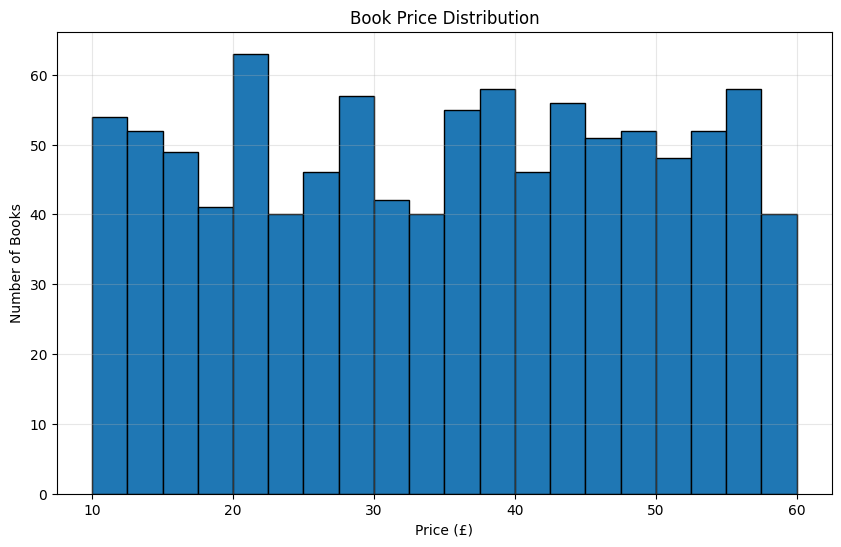

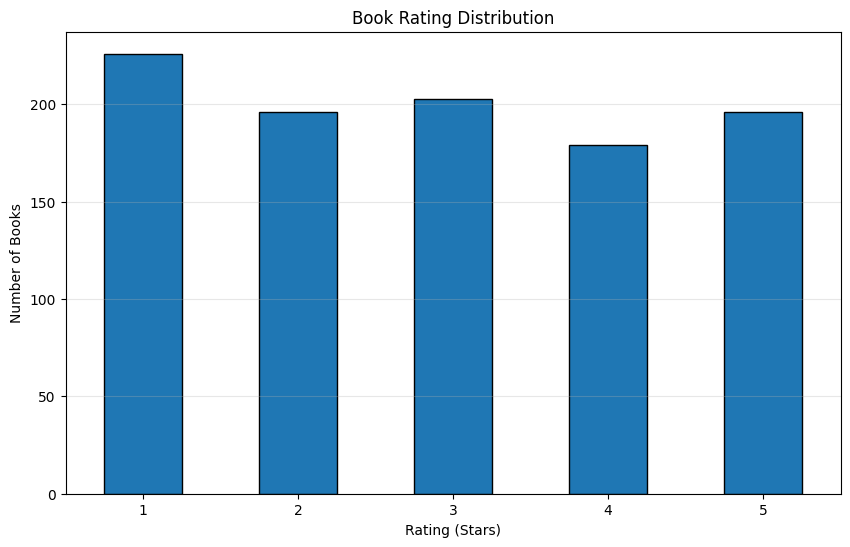

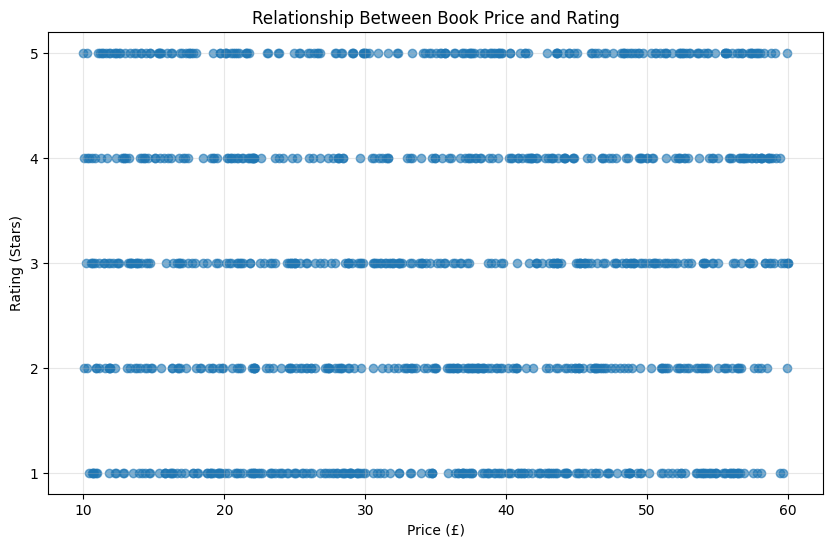

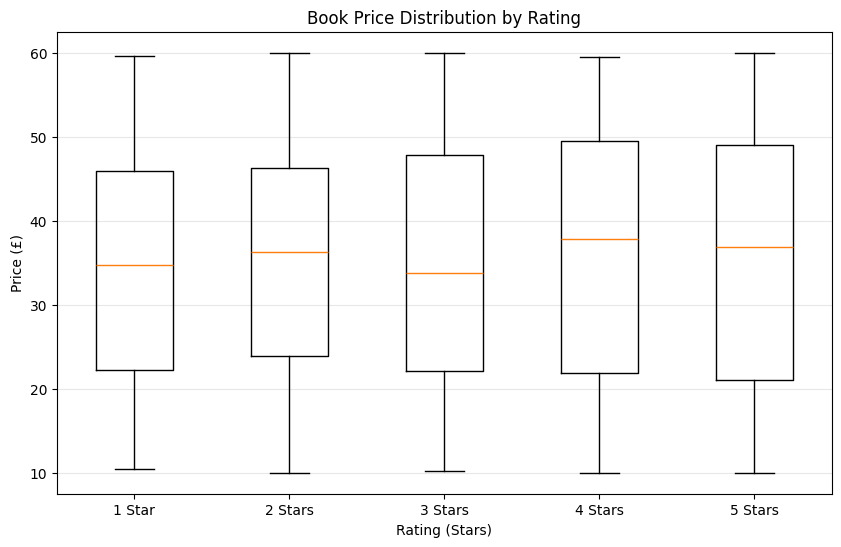

All four visualizations saved successfully!
Files: ['price_vs_rating.png', 'price_distribution.png', 'price_by_rating.png', 'rating_distribution.png']


In [28]:
import os
import matplotlib.pyplot as plt

# Create folder for visualizations
os.makedirs('visualizations', exist_ok=True)

# 1. Price distribution
plt.figure(figsize=(10, 6))
plt.hist(cleaned_books_df['price'], bins=20, edgecolor='black')
plt.title('Book Price Distribution')
plt.xlabel('Price (£)')
plt.ylabel('Number of Books')
plt.grid(alpha=0.3)
plt.savefig('visualizations/price_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()


# 2. Rating distribution
plt.figure(figsize=(10, 6))
cleaned_books_df['rating_score'].value_counts().sort_index().plot(
    kind='bar', edgecolor='black'
)
plt.title('Book Rating Distribution')
plt.xlabel('Rating (Stars)')
plt.ylabel('Number of Books')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.savefig('visualizations/rating_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()


# 3. Price vs Rating
plt.figure(figsize=(10, 6))
plt.scatter(
    cleaned_books_df['price'],
    cleaned_books_df['rating_score'],
    alpha=0.6
)
plt.title('Relationship Between Book Price and Rating')
plt.xlabel('Price (£)')
plt.ylabel('Rating (Stars)')
plt.yticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.3)
plt.savefig('visualizations/price_vs_rating.png',
            dpi=300, bbox_inches='tight')
plt.show()


# 4. Price by Rating
plt.figure(figsize=(10, 6))
rating_groups = [
    cleaned_books_df.loc[
        cleaned_books_df['rating_score'] == rating, 'price'
    ]
    for rating in range(1, 6)
]
plt.boxplot(rating_groups)
plt.title('Book Price Distribution by Rating')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price (£)')
plt.xticks([1, 2, 3, 4, 5],
           ['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'])
plt.grid(axis='y', alpha=0.3)
plt.savefig('visualizations/price_by_rating.png',
            dpi=300, bbox_inches='tight')
plt.show()


print("All four visualizations saved successfully!")
print("Files:", os.listdir('visualizations'))

In [29]:
import os

print("PROJECT FILE VERIFICATION")
print("=" * 45)

# Main files
main_files = [
    'scraped_books_cleaned.csv',
    'book_analysis_summary.csv'
]

for file in main_files:
    print(f"{file}: {'Available' if os.path.exists(file) else 'Missing'}")

# Visualization files
print("\nVISUALIZATION FILES")
print("=" * 45)

for file in os.listdir('visualizations'):
    print(file)

# Dataset information
print("\nDATASET INFORMATION")
print("=" * 45)
print("Total records:", len(cleaned_books_df))
print("Total columns:", len(cleaned_books_df.columns))
print("Columns:", list(cleaned_books_df.columns))

PROJECT FILE VERIFICATION
scraped_books_cleaned.csv: Available
book_analysis_summary.csv: Available

VISUALIZATION FILES
price_vs_rating.png
price_distribution.png
price_by_rating.png
rating_distribution.png

DATASET INFORMATION
Total records: 1000
Total columns: 10
Columns: ['title', 'price', 'currency', 'rating', 'availability', 'product_url', 'image_url', 'page_number', 'rating_score', 'price_category']


In [30]:
%%writefile scraper.py

import requests
import pandas as pd
import time
import logging

from bs4 import BeautifulSoup
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/"

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)

def extract_product(product, page_url):
    title = product.select_one('h3 a')['title']

    price_text = product.select_one('.price_color').get_text(strip=True)
    price = float(price_text.replace('Â£', '').replace('£', '').strip())

    rating = product.select_one('.star-rating')['class'][-1]
    availability = product.select_one('.availability').get_text(strip=True)

    product_url = urljoin(
        page_url,
        product.select_one('h3 a')['href']
    )

    image_url = urljoin(
        page_url,
        product.select_one('.image_container img')['src']
    )

    return {
        'title': title,
        'price': price,
        'currency': 'GBP',
        'rating': rating,
        'availability': availability,
        'product_url': product_url,
        'image_url': image_url
    }


def scrape_all_pages(start_url=BASE_URL):
    all_products = []
    current_url = start_url
    page_number = 1

    session = requests.Session()
    session.headers.update({
        'User-Agent': 'Mozilla/5.0 (compatible; EducationalBookScraper/1.0)'
    })

    while current_url:
        logging.info(f"Scraping page {page_number}")

        try:
            response = session.get(current_url, timeout=15)
            response.raise_for_status()

            soup = BeautifulSoup(response.text, 'html.parser')
            products = soup.find_all('article', class_='product_pod')

            for product in products:
                try:
                    product_data = extract_product(product, current_url)
                    product_data['page_number'] = page_number
                    all_products.append(product_data)

                except (AttributeError, KeyError, ValueError) as error:
                    logging.warning(f"Product extraction failed: {error}")

            next_button = soup.select_one('li.next a')

            if next_button:
                current_url = urljoin(current_url, next_button['href'])
                page_number += 1
                time.sleep(1)
            else:
                current_url = None

        except requests.exceptions.RequestException as error:
            logging.error(f"Request failed on page {page_number}: {error}")
            break

    session.close()

    df = pd.DataFrame(all_products)

    if not df.empty:
        df.to_csv('scraped_books.csv', index=False, encoding='utf-8')

    logging.info(f"Scraping finished. Total products: {len(df)}")

    return df


if __name__ == "__main__":
    books_df = scrape_all_pages()
    print("\nScraped dataset shape:", books_df.shape)
    print(books_df.head())

Writing scraper.py


In [31]:
import os

print("Scraper script exists:", os.path.exists('scraper.py'))
print("Script size:", round(os.path.getsize('scraper.py') / 1024, 2), "KB")

Scraper script exists: True
Script size: 2.79 KB


In [33]:
import os
import shutil

# Create main project directory
project_folder = 'Web_Scraping'

os.makedirs(project_folder, exist_ok=True)

# Create visualizations directory
os.makedirs(
    os.path.join(project_folder, 'visualizations'),
    exist_ok=True
)

print("Project folders created successfully!")

Project folders created successfully!


In [34]:
# Copy notebook-related project files
files_to_copy = [
    'scraper.py',
    'scraped_books_cleaned.csv',
    'book_analysis_summary.csv'
]

for file in files_to_copy:
    shutil.copy(file, project_folder)

# Copy visualization files
for file in os.listdir('visualizations'):
    source = os.path.join('visualizations', file)
    destination = os.path.join(
        project_folder, 'visualizations', file
    )
    shutil.copy(source, destination)

print("All project files copied successfully!")

All project files copied successfully!


In [35]:
for root, dirs, files in os.walk('Web_Scraping'):
    print(root)
    for file in files:
        print("  └──", file)

Web_Scraping
  └── scraped_books_cleaned.csv
  └── scraper.py
  └── book_analysis_summary.csv
Web_Scraping/visualizations
  └── price_vs_rating.png
  └── price_distribution.png
  └── price_by_rating.png
  └── rating_distribution.png
